In [11]:
import pandas as pd

df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [12]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [13]:
median_val = df['horsepower'].median()
median_val

np.float64(254.0)

In [14]:
import numpy as np

In [15]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [16]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [17]:
df_train_0 = df_train.fillna({'horsepower': 0})
df_val_0 = df_val.fillna({'horsepower': 0})

In [19]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [24]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight',
        'model_year']

In [20]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [37]:
X_train = df_train_0[base].values
w0, w = train_linear_regression(X_train, y_train)

In [38]:
y_pred = w0 + X_train.dot(w)

In [39]:
import seaborn as sns

<Axes: ylabel='Count'>

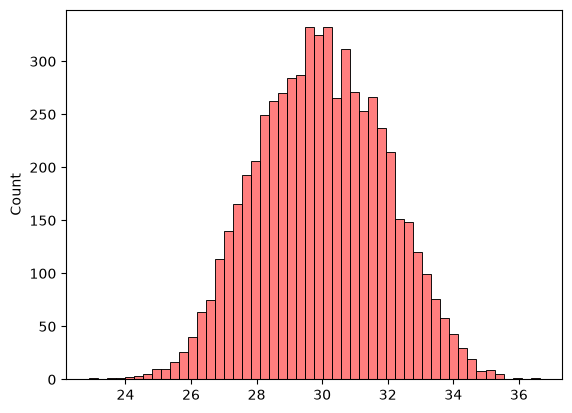

In [40]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)

In [41]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [44]:
rmse(y_val, y_pred)

ValueError: operands could not be broadcast together with shapes (2000,) (6000,) 

In [45]:
mean_hp = df_train['horsepower'].mean()

for name, fill in [('zero', 0), ('mean', mean_hp)]:
    X_train = df_train[base].fillna({'horsepower': fill}).values
    X_val = df_val[base].fillna({'horsepower': fill}).values

    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)          # предсказание на ВАЛИДАЦИИ

    print(name, round(rmse(y_val, y_pred), 3))

zero 2.205
mean 2.202


In [46]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [49]:
X_train = df_train_0[base].fillna({'horsepower': 0}).values
X_val = df_val_0[base].fillna({'horsepower': 0}).values

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    print(r, round(rmse(y_val, y_pred), 2))

0 2.21
0.01 2.21
0.1 2.22
1 2.35
5 2.41
10 2.42
100 2.43


In [50]:
def splitting(seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    return [df_train, df_val, df_test]

In [51]:
scores = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    df_tr, df_v, df_te = splitting(seed)

    y_tr = df_tr['fuel_efficiency_mpg'].values
    y_v = df_v['fuel_efficiency_mpg'].values

    X_tr = df_tr[base].fillna({'horsepower': 0}).values
    X_v = df_v[base].fillna({'horsepower': 0}).values

    w0, w = train_linear_regression(X_tr, y_tr)
    y_pred = w0 + X_v.dot(w)

    score = rmse(y_v, y_pred)
    scores.append(score)
    print(seed, round(score, 3))

print('std:', round(np.std(scores), 3))

0 2.239
1 2.202
2 2.163
3 2.204
4 2.202
5 2.246
6 2.27
7 2.191
8 2.217
9 2.207
std: 0.029


In [52]:
df_tr, df_v, df_te = splitting(9)

df_full_train = pd.concat([df_tr, df_v]).reset_index(drop=True)

y_full_train = df_full_train['fuel_efficiency_mpg'].values
y_te = df_te['fuel_efficiency_mpg'].values

X_full_train = df_full_train[base].fillna({'horsepower': 0}).values
X_te = df_te[base].fillna({'horsepower': 0}).values

w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
y_pred = w0 + X_te.dot(w)

print(round(rmse(y_te, y_pred), 3))

2.236
